# 03 — Encoder: fine-tuned mDeBERTa-v3 with long-text handling

Fine-tunes `microsoft/mdeberta-v3-base` (multilingual: EN + DE) on the fixed 40k train sample and compares three ways to handle texts longer than 512 tokens: **head** truncation, **head+tail**, and **chunk averaging** (sliding windows). Compared with the baseline on the same val split.

**Run on Kaggle**
1. *Create → New Notebook → File → Import Notebook* → upload this file.
2. *Settings*: Accelerator **GPU T4 x2**, Internet **On** (downloads Hugging Face weights).
3. *Add Input*: competition **ai-generated-text-detection-hw3-ucu-ai-2026**, and the output of your **02_baseline** notebook (*Add Input → Your Work → Notebooks*).
4. *Save Version → Save & Run All (Commit)*. **ETA: ~3 h (2 epochs ≈ 1.5–2 h, val+test inference ≈ 1 h).**

**Copy back into the repo** (from the version's *Output* tab):
- this notebook with outputs → `notebooks/03_encoder.ipynb`
- `encoder_results.csv`, `encoder_loss.png`, `cm_*.png` → `reports/` and `reports/figures/`
- keep `encoder_model/` and `encoder_*_logits.csv` only on Kaggle (inputs of 04/05)


In [1]:
import os, glob, re, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SMOKE = bool(os.environ.get('SMOKE'))  # tiny local dry-run of the whole notebook; never set on Kaggle
OUT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
OUT.mkdir(exist_ok=True)
SEED, LABELS = 42, ['human', 'ai', 'fusion']
L2I = {l: i for i, l in enumerate(LABELS)}

def find(name):
    """Locate an input file in attached Kaggle inputs (or ../data locally)."""
    for root in ['/kaggle/input', '../data', str(OUT)]:
        hits = sorted(glob.glob(f'{root}/**/{name}', recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(f'{name} not found: attach the inputs listed at the top of this notebook')

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")  # the competition metric

def report(y_true, y_pred, title):
    """Per-class metrics + normalized confusion matrix (labels are class indices)."""
    print(f'{title}: macro-F1 = {macro_f1(y_true, y_pred):.4f}')
    print(classification_report(y_true, y_pred, target_names=LABELS, digits=4))
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap='Blues', values_format='.3f')
    plt.title(title); plt.grid(False)
    plt.savefig(OUT / f"cm_{re.sub(r'[^a-z0-9]+', '_', title.lower())}.png", dpi=120, bbox_inches='tight'); plt.show()

def f1_by(df, pred_col, by):
    return df.groupby(by).apply(lambda d: macro_f1(d.y, d[pred_col])).round(4).rename('macro_f1').to_frame().join(df[by].value_counts().rename('n'))

train = pd.read_csv(find('train.csv'))
test = pd.read_csv(find('test.csv'))
sub = pd.read_csv(find('sample_submission.csv'))
if SMOKE:
    test = test.head(300); sub = sub[sub.id.isin(test.id)]
train['y'] = train.label.map(L2I)
print(train.shape, test.shape)

(272352, 6) (25000, 4)


In [2]:
split = pd.read_csv(find('split.csv'))
train = train.merge(split, on='id', validate='1:1')
val = train[train.is_val].reset_index(drop=True)
print('val rows:', len(val), '| fixed train sample:', (train.sample_rank >= 0).sum())

val rows: 27451 | fixed train sample: 60001


In [3]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding

MODEL = 'hf-internal-testing/tiny-random-deberta-v2' if SMOKE else 'microsoft/mdeberta-v3-base'
ENC_N = 400 if SMOKE else 40_000          # first ENC_N rows of the fixed train sample
MAX_LEN, STRIDE, MAX_CHUNKS = 512, 384, 8  # windows of 512 tokens, 128-token overlap, at most 8 per text
EPOCHS, LR = 2, 2e-5
print(torch.cuda.device_count(), 'GPU(s)')

tok = AutoTokenizer.from_pretrained(MODEL)
tr = train[(train.sample_rank >= 0) & (train.sample_rank < ENC_N)].reset_index(drop=True)
ids_of = lambda texts: tok(list(texts), add_special_tokens=False, truncation=False, verbose=False)['input_ids']
t = time.time()
ids_tr, ids_va, ids_te = ids_of(tr.text), ids_of(val.text), ids_of(test.text)
print(f'tokenized in {time.time() - t:.0f}s; val texts > {MAX_LEN} tokens: {np.mean([len(x) > MAX_LEN - 2 for x in ids_va]):.3f}')

2 GPU(s)


config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

tokenized in 95s; val texts > 512 tokens: 0.690


### Long-text strategies
- **head**: first 510 tokens.
- **head+tail**: first 255 + last 255 tokens (training input).
- **chunks**: up to 8 evenly spaced 510-token windows covering the whole text; logits averaged. Fusion texts are only *partially* rewritten, so looking at the whole text should help most there.

In [4]:
BODY = MAX_LEN - 2
wrap = lambda x: [tok.cls_token_id] + x + [tok.sep_token_id]
def head(ids): return wrap(ids[:BODY])
def head_tail(ids): return wrap(ids) if len(ids) <= BODY else wrap(ids[:BODY // 2] + ids[-(BODY - BODY // 2):])
def chunks(ids):
    if len(ids) <= BODY:
        return [wrap(ids)]
    n = min(int(np.ceil((len(ids) - BODY) / STRIDE)) + 1, MAX_CHUNKS)
    return [wrap(ids[s:s + BODY]) for s in np.linspace(0, len(ids) - BODY, n).astype(int)]

class DS(torch.utils.data.Dataset):
    def __init__(self, seqs, labels=None): self.seqs, self.labels = seqs, labels
    def __len__(self): return len(self.seqs)
    def __getitem__(self, i):
        d = {'input_ids': self.seqs[i], 'attention_mask': [1] * len(self.seqs[i])}
        if self.labels is not None:
            d['labels'] = int(self.labels[i])
        return d

## Training (head+tail inputs)

In [5]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=3, id2label=dict(enumerate(LABELS)), label2id=L2I,
                                                           dtype=torch.float32)  # fp32 master weights for fp16 AMP (v5 keeps checkpoint dtype)
rng = np.random.RandomState(SEED)
mon = rng.choice(len(val), min(3000, len(val)), replace=False)  # small val subset to monitor epochs
steps = int(np.ceil(len(tr) / (8 * 2 * max(torch.cuda.device_count(), 1)))) * EPOCHS  # batch 8 x accum 2 x GPUs
args = TrainingArguments(
    output_dir='/tmp/enc', num_train_epochs=EPOCHS, learning_rate=LR, warmup_steps=int(0.1 * steps), weight_decay=0.01,
    per_device_train_batch_size=8, gradient_accumulation_steps=2, per_device_eval_batch_size=32,
    fp16=torch.cuda.is_available(), eval_strategy='epoch', save_strategy='no', logging_steps=100,
    report_to='none', seed=SEED)
trainer = Trainer(model=model, args=args, data_collator=DataCollatorWithPadding(tok),
                  train_dataset=DS([head_tail(x) for x in ids_tr], tr.y.values),
                  eval_dataset=DS([head_tail(ids_va[i]) for i in mon], val.y.values[mon]),
                  compute_metrics=lambda p: {'macro_f1': macro_f1(p.label_ids, p.predictions.argmax(-1))})
t = time.time()
trainer.train()
print(f'trained in {(time.time() - t) / 60:.0f} min')
trainer.save_model(OUT / 'encoder_model'); tok.save_pretrained(OUT / 'encoder_model')

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.33GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/mdeberta-v3-base
Key                                        | Status     | 
-------------------------------------------+------------+-
mask_predictions.dense.weight              | UNEXPECTED | 
mask_predictions.classifier.bias           | UNEXPECTED | 
deberta.embeddings.word_embeddings._weight | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight    | UNEXPECTED | 
lm_predictions.lm_head.dense.bias          | UNEXPECTED | 
mask_predictions.LayerNorm.weight          | UNEXPECTED | 
mask_predictions.classifier.weight         | UNEXPECTED | 
lm_predictions.lm_head.bias                | UNEXPECTED | 
mask_predictions.LayerNorm.bias            | UNEXPECTED | 
lm_predictions.lm_head.dense.weight        | UNEXPECTED | 
mask_predictions.dense.bias                | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight 

Epoch,Training Loss,Validation Loss,Macro F1
1,0.957470,0.420687,0.891130
2,0.663816,0.416845,0.900489


trained in 126 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/kaggle/working/encoder_model/tokenizer_config.json',
 '/kaggle/working/encoder_model/tokenizer.json')

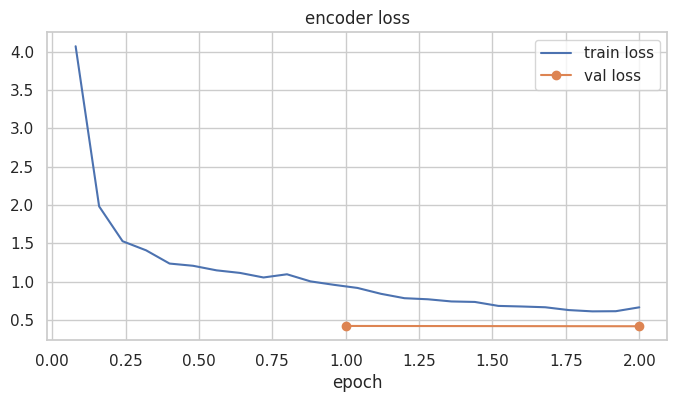

,epoch,eval_loss,eval_macro_f1
12,1.0,0.420687,0.891130
26,2.0,0.416845,0.900489


In [6]:
log = pd.DataFrame(trainer.state.log_history)
ax = log.dropna(subset=['loss']).plot(x='epoch', y='loss', label='train loss', figsize=(8, 4))
log.dropna(subset=['eval_loss']).plot(x='epoch', y='eval_loss', marker='o', label='val loss', ax=ax)
plt.title('encoder loss'); plt.savefig(OUT / 'encoder_loss.png', dpi=120, bbox_inches='tight'); plt.show()
log.dropna(subset=['eval_loss'])[['epoch', 'eval_loss', 'eval_macro_f1']]

**Observations.** The second epoch helps only a little: on the 3k monitoring rows, val loss goes 0.421 → 0.417 and macro-F1 0.891 → 0.900.

## Inference with each long-text strategy

In [7]:
def predict(seqs):
    order = np.argsort([len(s) for s in seqs])  # length-sorted batches = less padding
    out = trainer.predict(DS([seqs[i] for i in order])).predictions
    logits = np.empty_like(out); logits[order] = out
    return logits

def predict_chunks(ids_list):
    owner, seqs = [], []
    for i, ids in enumerate(ids_list):
        for c in chunks(ids):
            owner.append(i); seqs.append(c)
    lg, owner = predict(seqs), np.array(owner)
    agg = np.zeros((len(ids_list), lg.shape[1])); np.add.at(agg, owner, lg)
    return agg / np.bincount(owner)[:, None]

STRATS = {'head': lambda L: predict([head(x) for x in L]), 'head_tail': lambda L: predict([head_tail(x) for x in L]), 'chunks': predict_chunks}
val_logits = {}
for name, f in STRATS.items():
    t = time.time(); val_logits[name] = f(ids_va)
    print(f'{name}: val macro-F1 {macro_f1(val.y, val_logits[name].argmax(1)):.4f} ({time.time() - t:.0f}s)')

head: val macro-F1 0.8166 (750s)


head_tail: val macro-F1 0.8999 (752s)


chunks: val macro-F1 0.8801 (2031s)


## Comparison with the baseline (same val split) and overfitting check

In [8]:
bl = val[['id', 'y']].merge(pd.read_csv(find('baseline_val_scores.csv')), on='id')
rows = [{'model': 'TF-IDF baseline (02)', 'val_macro_f1': macro_f1(bl.y, bl[[f'base_{l}' for l in LABELS]].values.argmax(1))}]
rows += [{'model': f'mDeBERTa, {k}', 'val_macro_f1': macro_f1(val.y, v.argmax(1))} for k, v in val_logits.items()]
mon_tr = rng.choice(len(tr), min(3000, len(tr)), replace=False)
rows.append({'model': 'mDeBERTa, head_tail on 3k TRAIN rows (overfit check)', 'val_macro_f1': macro_f1(tr.y.values[mon_tr], predict([head_tail(ids_tr[i]) for i in mon_tr]).argmax(1))})
enc_res = pd.DataFrame(rows).round(4)
enc_res.to_csv(OUT / 'encoder_results.csv', index=False)
enc_res

,model,val_macro_f1
0,TF-IDF baseline (02),0.8796
1,"mDeBERTa, head",0.8166
2,"mDeBERTa, head_tail",0.8999
3,"mDeBERTa, chunks",0.8801
4,"mDeBERTa, head_tail on 3k TRAIN rows (overfit ...",0.9287


**Observations.** The long-text strategy matters: **head+tail 0.900**, chunks 0.880, head only 0.817. Dropping the end of the text costs 0.08, so the ending carries much of the signal. Averaging chunks is worse than head+tail: the model was trained on head+tail inputs, and averaging over all windows likely dilutes the few windows that were actually rewritten. With head+tail the encoder beats the 60k TF-IDF baseline by +0.020 on the same split; the TF-IDF model refit on all data (02b, 0.898) is about as good. The train–val gap is moderate (0.929 vs 0.900).

best strategy: head_tail
Encoder val (head_tail): macro-F1 = 0.8999
              precision    recall  f1-score   support

       human     0.8449    0.8266    0.8356      6723
          ai     0.9929    0.9960    0.9945     12239
      fusion     0.8641    0.8751    0.8696      8489

    accuracy                         0.9171     27451
   macro avg     0.9007    0.8992    0.8999     27451
weighted avg     0.9168    0.9171    0.9169     27451



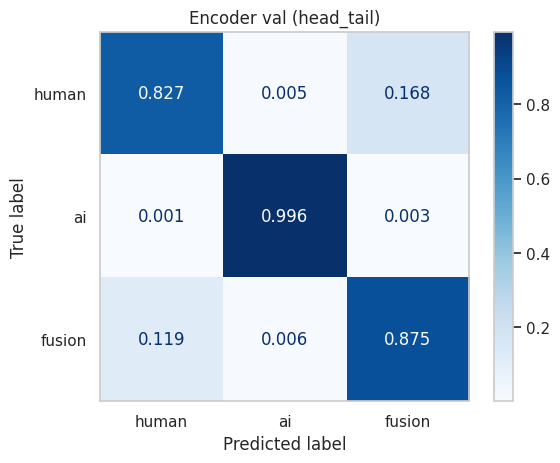

,macro_f1,n
lang,,
de-DE,0.9007,5383
en-EN,0.8997,22068


,macro_f1,n
domain,,
arxiv_papers,0.7444,1378
blog_authorship_corpus,0.8310,4004
bundestag,0.9007,5343
cnn_news,0.9486,4436
euro_court_cases,0.8311,2776
gutenberg,0.7357,723
house_of_commons,0.9101,3117
student_essays,0.9373,5674


In [9]:
BEST = max(val_logits, key=lambda k: macro_f1(val.y, val_logits[k].argmax(1)))
print('best strategy:', BEST)
val['pred'] = val_logits[BEST].argmax(1)
report(val.y, val.pred, f'Encoder val ({BEST})')
display(f1_by(val, 'pred', 'lang'), f1_by(val, 'pred', 'domain'))

**Observations.** As with the baseline, `ai` is nearly perfect (0.995) and the errors are human ↔ fusion (0.836 / 0.870). Unlike TF-IDF, the encoder scores both languages equally (0.90). It is weakest on arxiv (0.74) and gutenberg (0.74), the two domains where TF-IDF does better (0.86 / 0.89). Both are almost entirely ai, so the encoder and TF-IDF make different errors, which motivates stacking (04).

## Test predictions, saved logits, submission

In [10]:
test_logits = STRATS[BEST](ids_te)
cols = [f'enc_{l}' for l in LABELS]
pd.DataFrame(val_logits[BEST], columns=cols).assign(id=val.id.values).to_csv(OUT / 'encoder_val_logits.csv', index=False)
pd.DataFrame(test_logits, columns=cols).assign(id=test.id.values).to_csv(OUT / 'encoder_test_logits.csv', index=False)

pred = pd.DataFrame({'id': test.id, 'label': np.array(LABELS)[test_logits.argmax(1)]})
submission = sub[['id']].merge(pred, on='id', how='left')
assert len(submission) == len(sub) and submission.label.isin(LABELS).all()
submission.to_csv(OUT / 'submission_encoder.csv', index=False)
print(submission.label.value_counts(normalize=True).round(3))

label
ai        0.516
fusion    0.245
human     0.239
Name: proportion, dtype: float64
